# Rating plateaus on Lichess: can we detect them, and predict who breaks out?

**Marko Antolčić · NeuralGambit research**

A player rated 1600 for months might be stuck, or might be improving while meeting stronger opponents.
This notebook separates two problems:

1. **Detection.** Is the rating trajectory flat right now? This is a *change-point* problem.
2. **Prediction.** Given the recent trajectory, will the player gain at least **+75 rating points in the next 100 games**? This is a *supervised learning* problem.

It then answers five research questions:

- **Q1.** Are plateaus more common at certain rating levels?
- **Q2.** Does rating volatility predict later improvement?
- **Q3.** Does playing more games help players escape plateaus?
- **Q4.** Do changes in playing style come before plateaus?
- **Q5.** Can a player's play improve while their rating stays flat, and does accuracy improve *before* rating does?

The trained model runs in the [NeuralGambit Plateau Detector](https://www.neuralgambit.com/stats/plateau).

## Data

- **Cohort.** Players who played rated blitz in the January 2021 [Lichess database](https://database.lichess.org) dump, whose accounts were created between July 2020 and January 2021, and who went on to play at least 300 rated blitz games. Accounts flagged for Terms of Service violations or closed were removed. Sampling from a 2021 dump, not a current one, keeps players who later quit.
- **Games.** Each player's first 700 rated blitz games, downloaded from the Lichess API (`pipeline/s02_fetch_games.py`), with ratings, opponents, results, openings, moves and clocks.
- **Engine analysis.** Stockfish analysed every 4th game of a subset of players (`pipeline/s04_stockfish.py`) to measure accuracy (Lichess's formula), mistakes and blunders.
- **Windows.** Each history is cut into **100-game windows**, sliding by 25 games, skipping the first 30 (provisional) games. Each window gets the features below and the outcome over the **next 100 games**.

Lichess uses Glicko-2, not Elo, so "rating" here means the Lichess blitz rating.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
try:
    display
except NameError:  # running as a plain script
    display = print

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from pipeline.common import DATA, OUT
from pipeline.features import FEATURES, FLAT_TREND, GAIN, SKIP, WINDOW, segment, trend_per_window
from pipeline import model as M

FIG = OUT / "fig"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, GREEN, ORANGE, GREY, RED = "#2b6cb0", "#629924", "#d97706", "#8a8f98", "#c53030"
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

GAME_COLS = ["player", "idx", "ts", "rating_before", "rating_after", "rating_diff", "opp_rating", "score",
             "status", "eco", "plies", "time_use"]  # everything except the move lists, to save memory
games = pd.read_parquet(DATA / "games.parquet", columns=GAME_COLS)
w = pd.read_parquet(DATA / "windows.parquet")
w["time_use"] = w["time_use"].fillna(w["time_use"].median())
BANDS = [0, 1200, 1400, 1600, 1800, 2000, 3500]
LABELS = ["<1200", "1200–1400", "1400–1600", "1600–1800", "1800–2000", "2000+"]
w["band"] = pd.cut(w["rating"], BANDS, labels=LABELS, right=False)

summary = pd.Series({
    "Players": games.player.nunique(), "Games": len(games),
    "Median games per player": int(games.groupby("player").size().median()),
    "100-game windows": len(w), "Windows on a plateau": f"{w.flat.mean():.0%}",
    f"Windows followed by +{GAIN}": f"{w.improve.mean():.0%}",
})
summary.to_frame("value")

,value
Players,581
Games,385840
Median games per player,700
100-game windows,10242
Windows on a plateau,36%
Windows followed by +75,13%


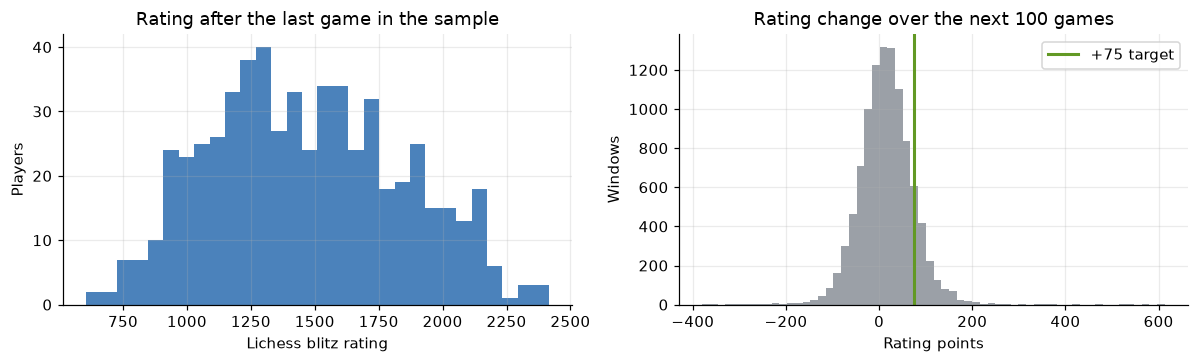

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
last = games.groupby("player").rating_after.last()
ax[0].hist(last, bins=30, color=BLUE, alpha=.85)
ax[0].set(title="Rating after the last game in the sample", xlabel="Lichess blitz rating", ylabel="Players")
ax[1].hist(w.future_gain, bins=60, color=GREY, alpha=.85)
ax[1].axvline(GAIN, color=GREEN, lw=2, label=f"+{GAIN} target")
ax[1].set(title="Rating change over the next 100 games", xlabel="Rating points", ylabel="Windows")
ax[1].legend(); save("cohort")

## Problem 1: detecting a flat trajectory

Ratings are noisy: a blitz rating moves about 6 points per game, so even a player whose strength is not changing drifts up and down. Two detectors are compared:

- **Window rule (used by the dashboard).** Fit a straight line through the last 100 ratings. The window is **flat** if the fitted change over those 100 games is smaller than ±30 points.
- **Change-point segmentation.** Binary segmentation splits a player's whole history wherever two straight lines fit much better than one (minimum 50 games per segment). Each segment is then labelled climbing, flat or falling by the same ±30 rule.

Why ±30? The plot below shows the fitted 100-game change across all windows. The bulk around zero is the "nothing is really changing" noise. The cut-off sits near its edge, so a flat window is one whose movement is about the size of normal noise.

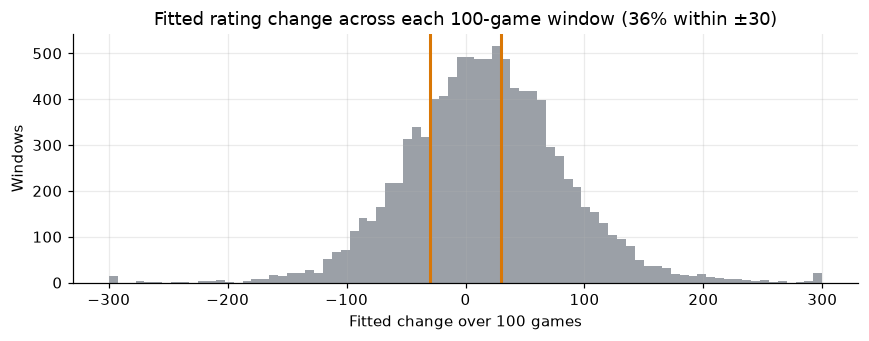

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(w.trend.clip(-300, 300), bins=80, color=GREY, alpha=.85)
for x in (-FLAT_TREND, FLAT_TREND):
    ax.axvline(x, color=ORANGE, lw=2)
ax.set(title=f"Fitted rating change across each 100-game window ({w.flat.mean():.0%} within ±{FLAT_TREND})",
       xlabel="Fitted change over 100 games", ylabel="Windows")
save("trend-distribution")

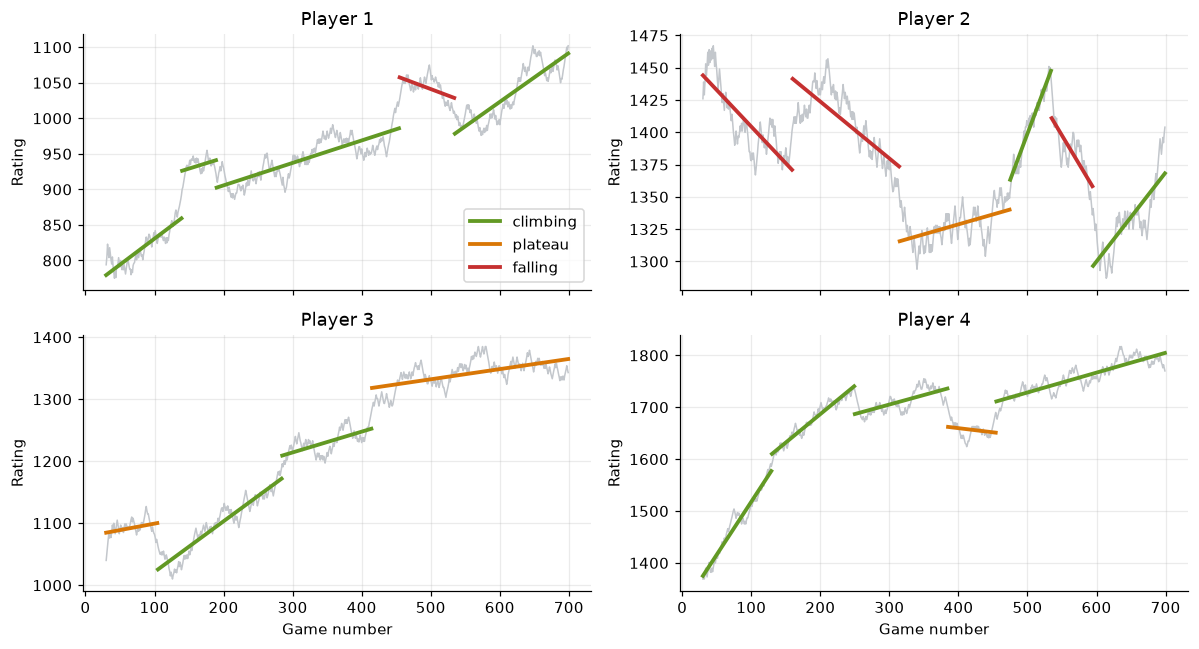

In [4]:
def segments_for(pid):
    y = games.loc[games.player == pid, "rating_after"].to_numpy()[SKIP:]
    return y, segment(y)

def kind(t): return "flat" if abs(t) < FLAT_TREND else ("up" if t > 0 else "down")
COL = {"flat": ORANGE, "up": GREEN, "down": RED}

examples = (games.groupby("player").size().loc[lambda s: s >= 600].sample(4, random_state=3).index)
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, pid in zip(axes.flat, examples):
    y, segs = segments_for(pid)
    ax.plot(np.arange(len(y)) + SKIP, y, color="#c3c7cc", lw=1)
    for a, b, t in segs:
        x = np.arange(a, b); xc = x - x.mean()
        fit = y[a:b].mean() + t / WINDOW * xc
        ax.plot(x + SKIP, fit, color=COL[kind(t)], lw=2.5)
    ax.set(title=f"Player {list(examples).index(pid) + 1}", ylabel="Rating")
for ax in axes[1]: ax.set_xlabel("Game number")
axes[0, 0].plot([], [], color=GREEN, lw=2.5, label="climbing"); axes[0, 0].plot([], [], color=ORANGE, lw=2.5, label="plateau")
axes[0, 0].plot([], [], color=RED, lw=2.5, label="falling"); axes[0, 0].legend(loc="lower right")
save("segment-examples")

In [5]:
seg_rows = []
for pid, g in games.groupby("player"):
    y = g.rating_after.to_numpy()[SKIP:]
    for a, b, t in segment(y):
        seg_rows.append({"player": pid, "start": a + SKIP, "end": b + SKIP, "len": b - a, "trend": t,
                         "kind": kind(t), "rating": y[a:b].mean()})
segs = pd.DataFrame(seg_rows)
segs["band"] = pd.cut(segs.rating, BANDS, labels=LABELS, right=False)

# Agreement: is a window's last game inside a flat segment?
def seg_kind_at(pid, idx):
    s = segs[(segs.player == pid) & (segs.start <= idx) & (segs.end > idx)]
    return s.kind.iloc[0] if len(s) else None
w["seg_kind"] = [seg_kind_at(p, e - 1) for p, e in zip(w.player, w.end)]
agree = pd.crosstab(w.flat.map({True: "window flat", False: "window not flat"}), w.seg_kind, normalize="index").round(2)
print(f"{len(segs):,} segments; {segs.kind.value_counts(normalize=True).round(2).to_dict()}")
print(f"Median plateau segment: {segs.loc[segs.kind == 'flat', 'len'].median():.0f} games")
agree

2,312 segments; {'up': 0.38, 'flat': 0.37, 'down': 0.25}
Median plateau segment: 184 games


seg_kind,down,flat,up
flat,,,
window flat,0.09,0.69,0.23
window not flat,0.18,0.41,0.41


The two detectors mostly agree. The window rule reacts faster, because it only looks at the last 100 games, so it also flags the flat tops of short climbs. The segmentation needs the whole history, including games that haven't been played yet, so it can't be used live. The dashboard therefore uses the window rule and draws the segmentation only as context.

## Q1. Are plateaus more common at certain rating levels?

,windows,plateau_share,improve_rate,mean_trend,median_plateau_games
band,,,,,
<1200,3160,0.35,0.17,16.79,190.0
1200–1400,1884,0.37,0.13,18.23,185.0
1400–1600,1618,0.35,0.13,18.19,182.5
1600–1800,1533,0.35,0.10,16.43,180.0
1800–2000,1165,0.41,0.08,12.89,172.5
2000+,882,0.39,0.06,19.70,188.0


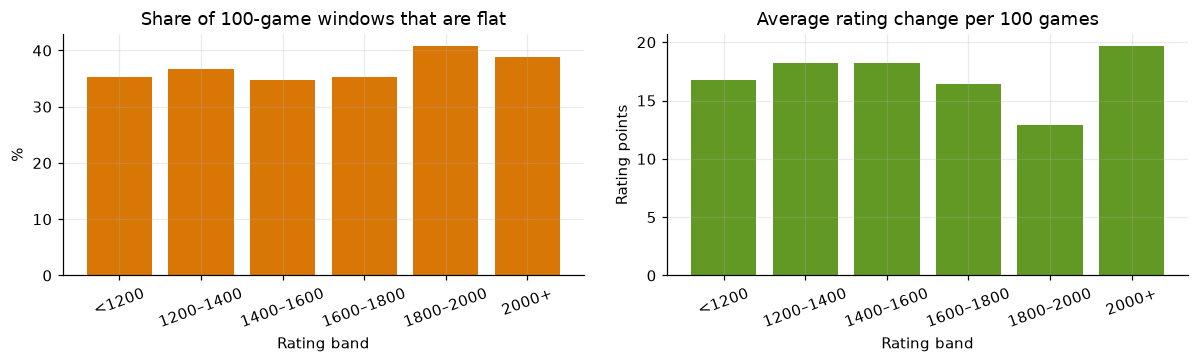

In [6]:
q1 = (w.groupby("band", observed=True)
        .agg(windows=("flat", "size"), plateau_share=("flat", "mean"), improve_rate=("improve", "mean"),
             mean_trend=("trend", "mean")))
plateau_len = segs[segs.kind == "flat"].groupby("band", observed=True)["len"].median().rename("median_plateau_games")
q1 = q1.join(plateau_len)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(q1.index.astype(str), q1.plateau_share * 100, color=ORANGE)
ax[0].set(title="Share of 100-game windows that are flat", ylabel="%", xlabel="Rating band")
ax[1].bar(q1.index.astype(str), q1.mean_trend, color=[GREEN if v > 0 else RED for v in q1.mean_trend])
ax[1].set(title="Average rating change per 100 games", ylabel="Rating points", xlabel="Rating band")
for a in ax: a.tick_params(axis="x", rotation=20)
save("q1-plateau-by-band")
q1.round(2)

In [7]:
q1_test = smf.logit("flat ~ C(band)", data=w.assign(flat=w.flat.astype(int))).fit(disp=0, cov_type="cluster",
                                                                                     cov_kwds={"groups": pd.factorize(w.player)[0]})
print(f"Likelihood-ratio test that plateau share differs by band: p = {q1_test.llr_pvalue:.2g} "
      "(standard errors clustered by player)")

Likelihood-ratio test that plateau share differs by band: p = 0.006 (standard errors clustered by player)


## Problem 2: predicting improvement

**Target:** the rating 100 games later (average of games 91–100 ahead) is at least **+75** above the current rating (average of the last 10 games).

**Features** (all from the last 100 games, so they can be computed for any Lichess player):

| Feature | Meaning |
| --- | --- |
| rating | Current rating (mean of last 10 games) |
| trend / trend_recent | Fitted rating change over the last 100 / 25 games |
| volatility / resid_sd | Per-game rating swings / scatter around the trend line |
| win_rate, draw_rate | Results |
| opp_diff | Average opponent rating minus own rating |
| games_per_week, max_gap_days, days_since_prev | Playing frequency and breaks |
| below_peak | Distance below the player's best rating so far |
| career_games | Rated blitz games played so far |
| opening_entropy | Variety of openings (ECO families) |
| avg_plies, timeout_share, time_use | Game length, losses/wins on time, share of the clock used |

Models are evaluated with **5-fold cross-validation grouped by player**: a player's windows are never in both the training and the test fold, which would otherwise leak their personal trend into the test set.

In [8]:
scores, oof = M.cross_validate(w)
scores.pivot(index="model", columns="subset", values=["AUC", "Brier"]).round(3)

AUC                       Brier  \
subset                           All windows Plateau windows All windows   
model                                                                      
All features (gradient boosting)       0.627           0.608       0.108   
All features (logistic)                0.628           0.619       0.108   
Rating only (logistic)                 0.597           0.600       0.109   

                                                  
subset                           Plateau windows  
model                                             
All features (gradient boosting)           0.101  
All features (logistic)                    0.099  
Rating only (logistic)                     0.100

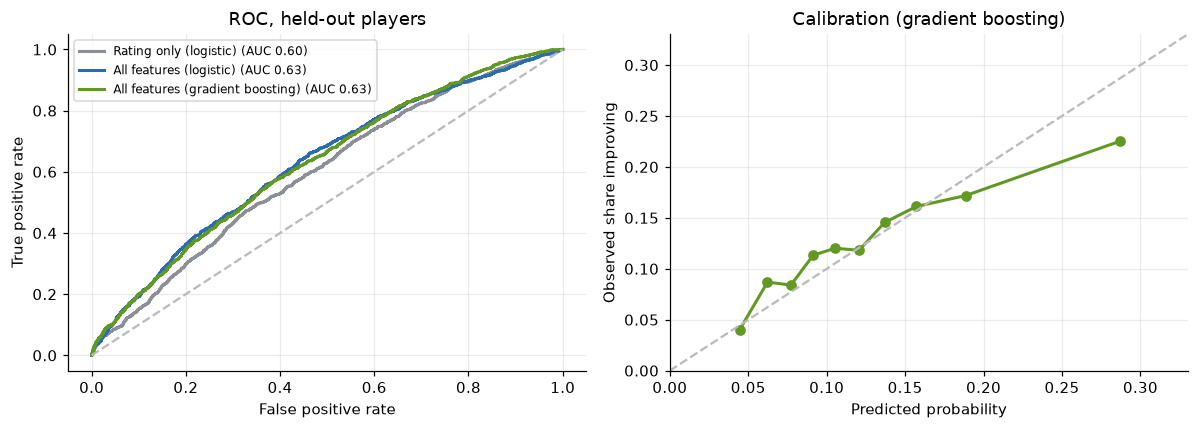

In [9]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y = w.improve.astype(int)
for name, c in zip(oof.columns, [GREY, BLUE, GREEN]):
    fpr, tpr, _ = roc_curve(y, oof[name])
    auc = scores.query("model == @name and subset == 'All windows'").AUC.iloc[0]
    ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {auc:.2f})")
ax[0].plot([0, 1], [0, 1], ls="--", color="#bbb")
ax[0].set(title="ROC, held-out players", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8)
gb = oof["All features (gradient boosting)"]
pt, pp = calibration_curve(y, gb, n_bins=10, strategy="quantile")
ax[1].plot(pp, pt, "o-", color=GREEN, lw=2); ax[1].plot([0, 1], [0, 1], ls="--", color="#bbb")
ax[1].set(title="Calibration (gradient boosting)", xlabel="Predicted probability", ylabel="Observed share improving",
          xlim=(0, max(pp) * 1.15), ylim=(0, max(pp) * 1.15))
save("model-evaluation")

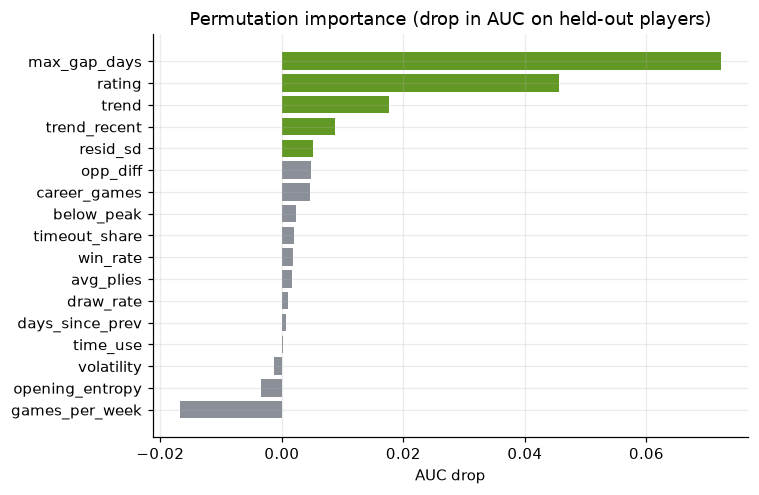

In [10]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(1, test_size=.3, random_state=0).split(w, groups=w.player))
gbm = M.fit_final(w.iloc[tr])
imp = permutation_importance(gbm, w.iloc[te][FEATURES], w.iloc[te].improve.astype(int), scoring="roc_auc",
                             n_repeats=10, random_state=0)
imp = pd.Series(imp.importances_mean, FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp.index, imp.values, color=[GREEN if v > 0.005 else GREY for v in imp.values])
ax.set(title="Permutation importance (drop in AUC on held-out players)", xlabel="AUC drop")
save("feature-importance")

### Why do breaks matter?

The longest break inside the window is the strongest single predictor. Two explanations are possible:

- **Players come back stronger** (they studied, or rested), so breaks lead to *gains*.
- **A rating-system effect.** Glicko-2 becomes less certain about a player who has not played, so after a break each game moves the rating more. Big moves become more likely in *both* directions.

If the second explanation is right, breaks should raise the chance of a big **drop** as much as a big **gain**.

,windows,big_gain,big_drop,mean_change
gap,,,,
<1 day,4053,0.092,0.043,10.047
1–3 days,3373,0.125,0.036,16.689
3–7 days,1427,0.164,0.045,21.337
1–4 weeks,897,0.202,0.064,24.608
4+ weeks,492,0.179,0.110,13.655


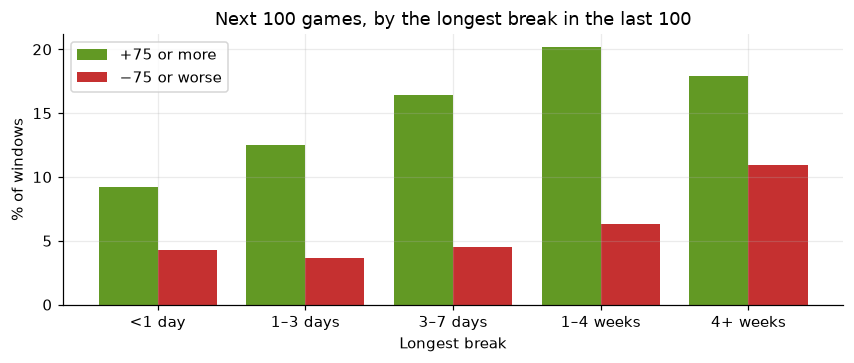

In [11]:
gap_bins = [0, 1, 3, 7, 30, 1e9]
gap_labs = ["<1 day", "1–3 days", "3–7 days", "1–4 weeks", "4+ weeks"]
gap = (w.assign(gap=pd.cut(w.max_gap_days, gap_bins, labels=gap_labs, right=False),
                gain=w.future_gain >= GAIN, drop=w.future_gain <= -GAIN)
         .groupby("gap", observed=True).agg(windows=("gain", "size"), big_gain=("gain", "mean"),
                                            big_drop=("drop", "mean"), mean_change=("future_gain", "mean")))
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(gap))
ax.bar(x - .2, gap.big_gain * 100, .4, color=GREEN, label=f"+{GAIN} or more")
ax.bar(x + .2, gap.big_drop * 100, .4, color=RED, label=f"−{GAIN} or worse")
ax.set_xticks(x, gap.index.astype(str))
ax.set(title="Next 100 games, by the longest break in the last 100", xlabel="Longest break", ylabel="% of windows")
ax.legend(); save("breaks")
gap.round(3)

## Q2. Does rating volatility predict later improvement?

Two kinds of volatility are separated. **Per-game swings** (`volatility`) are mostly Glicko's rating deviation: they are large for new or returning players. **Scatter around the trend** (`resid_sd`) captures streaky results. The question is asked within plateau windows, controlling for rating, trend and how far below their peak the player is.

,odds ratio per 1 SD,p
volatility_z,0.994,0.892
resid_sd_z,1.151,0.016
rating_z,0.692,0.000
trend_z,0.957,0.421
below_peak_z,1.110,0.057
career_games_z,0.945,0.371


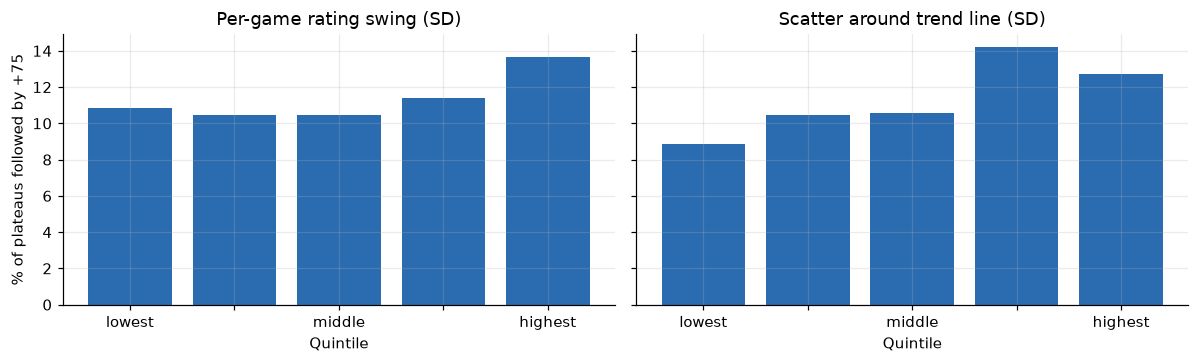

In [12]:
flat = w[w.flat].copy()
flat["improve_i"] = flat.improve.astype(int)
z = lambda s: (s - s.mean()) / s.std()
for c in ["volatility", "resid_sd", "rating", "trend", "below_peak", "games_per_week", "career_games"]:
    flat[c + "_z"] = z(flat[c])
groups = pd.factorize(flat.player)[0]
q2 = smf.logit("improve_i ~ volatility_z + resid_sd_z + rating_z + trend_z + below_peak_z + career_games_z",
               data=flat).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})
q2_tab = pd.DataFrame({"odds ratio per 1 SD": np.exp(q2.params), "p": q2.pvalues}).drop("Intercept").round(3)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, col, lab in [(ax[0], "volatility", "Per-game rating swing (SD)"), (ax[1], "resid_sd", "Scatter around trend line (SD)")]:
    b = flat.groupby(pd.qcut(flat[col], 5), observed=True).improve.agg(["mean", "count"])
    a.bar(range(5), b["mean"] * 100, color=BLUE)
    a.set_xticks(range(5), ["lowest", "", "middle", "", "highest"])
    a.set(title=lab, xlabel="Quintile")
ax[0].set_ylabel(f"% of plateaus followed by +{GAIN}")
save("q2-volatility")
q2_tab

## Q3. Does playing more games help players escape plateaus?

Comparing players with each other mixes "plays a lot" with "is a keen, improving player". So frequency is also tested **within players**: a conditional (fixed-effects) model compares the same player's busy and quiet plateaus. The outcome is measured over the next 100 *games*, so this asks whether games played close together are worth more than the same number spread out.

,odds ratio per doubling of games/week,p,windows
Between players,0.845,0.000,3731
Within players (fixed effects),0.826,0.015,1656


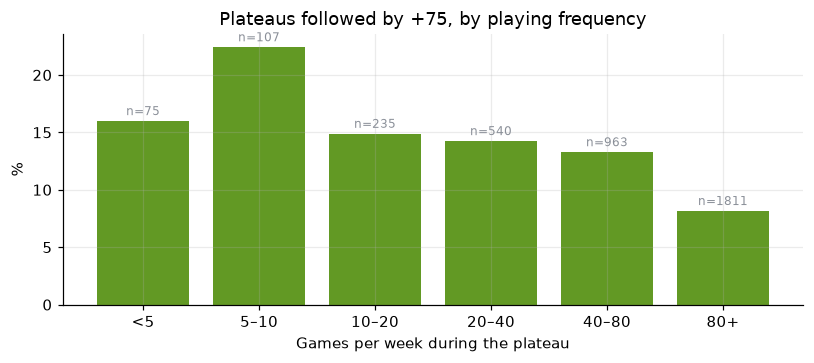

In [13]:
flat["log_gpw"] = np.log(flat.games_per_week)
between = smf.logit("improve_i ~ log_gpw + rating_z + trend_z + below_peak_z + career_games_z", data=flat).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": groups})
from statsmodels.discrete.conditional_models import ConditionalLogit
multi = flat.groupby("player").filter(lambda d: d.improve_i.nunique() == 2)
within = ConditionalLogit(multi.improve_i, multi[["log_gpw", "rating_z", "trend_z", "below_peak_z", "career_games_z"]],
                          groups=multi.player).fit(disp=0)
q3_tab = pd.DataFrame({
    "odds ratio per doubling of games/week": [np.exp(between.params["log_gpw"] * np.log(2)), np.exp(within.params["log_gpw"] * np.log(2))],
    "p": [between.pvalues["log_gpw"], within.pvalues["log_gpw"]],
    "windows": [len(flat), len(multi)]}, index=["Between players", "Within players (fixed effects)"]).round(3)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bins = [0, 5, 10, 20, 40, 80, 1e9]
labs = ["<5", "5–10", "10–20", "20–40", "40–80", "80+"]
b = flat.groupby(pd.cut(flat.games_per_week, bins, labels=labs), observed=True).improve.agg(["mean", "count"])
ax.bar(b.index.astype(str), b["mean"] * 100, color=GREEN)
for i, (m, n) in enumerate(zip(b["mean"], b["count"])):
    ax.text(i, m * 100 + .5, f"n={n}", ha="center", fontsize=8, color=GREY)
ax.set(title=f"Plateaus followed by +{GAIN}, by playing frequency", xlabel="Games per week during the plateau", ylabel="%")
save("q3-frequency")
q3_tab

**A check against the rating system.** Fewer games per week means more breaks, and after a break Glicko-2 moves the rating faster in *both* directions. A yes/no "+75" target can't tell "moves more" from "moves up". So the table below also shows big drops, and the regression uses the **average rating change** over the next 100 games, which bigger swings in both directions do not inflate. It includes a fixed effect for every player.

In [14]:
q3_check = (flat.assign(drop=flat.future_gain <= -GAIN, abs_move=flat.future_gain.abs())
                .groupby(pd.cut(flat.games_per_week, bins, labels=labs), observed=True)
                .agg(windows=("improve", "size"), big_gain=("improve", "mean"), big_drop=("drop", "mean"),
                     mean_change=("future_gain", "mean"), mean_abs_move=("abs_move", "mean")).round(3))
fe = smf.ols("future_gain ~ log_gpw + I(log_gpw ** 2) + rating_z + trend_z + below_peak_z + career_games_z + C(player)",
             data=flat).fit(cov_type="cluster", cov_kwds={"groups": groups})
peak_gpw = np.exp(-fe.params["log_gpw"] / (2 * fe.params["I(log_gpw ** 2)"]))
print(f"Within-player model of the average change: linear p = {fe.pvalues['log_gpw']:.3f}, "
      f"squared p = {fe.pvalues['I(log_gpw ** 2)']:.3f}; best pace ≈ {peak_gpw:.0f} games per week")
q3_check

Within-player model of the average change: linear p = 0.009, squared p = 0.005; best pace ≈ 35 games per week


,windows,big_gain,big_drop,mean_change,mean_abs_move
games_per_week,,,,,
<5,75,0.160,0.120,8.212,59.796
5–10,107,0.224,0.056,28.640,56.038
10–20,235,0.149,0.068,15.572,50.777
20–40,540,0.143,0.037,18.578,45.792
40–80,963,0.133,0.022,19.586,41.618
80+,1811,0.082,0.041,11.398,38.555


## Q4. Do changes in playing style come before plateaus?

A **plateau onset** is where a climbing segment is followed by a flat segment. The comparison is a climbing segment followed by another climb or a fall. For each style measure, the change from the 100 games before the transition to the 100 games after it is compared between the two groups, alongside an event-study plot centred on the onset.

In [15]:
STYLE = {"opening_entropy": "Opening variety (bits)", "avg_plies": "Game length (plies)",
         "timeout_share": "Games ending on time", "time_use": "Share of clock used"}
games["eco2"] = games.eco.str[:2]
gi = games.set_index(["player", "idx"]).sort_index()

def style_block(pid, a, b):
    d = gi.loc[pid].loc[a:b - 1]
    p = d.eco2.value_counts(normalize=True).to_numpy()
    return {"opening_entropy": -(p * np.log2(p)).sum(), "avg_plies": d.plies.mean(),
            "timeout_share": (d.status == "outoftime").mean(), "time_use": d.time_use.mean()}

events = []
for pid, s in segs.groupby("player"):
    s = s.sort_values("start").reset_index(drop=True)
    n = gi.loc[pid].index.max() + 1
    for i in range(1, len(s)):
        if s.kind[i - 1] != "up":
            continue
        t0 = s.start[i]
        if t0 - 100 < SKIP or t0 + 100 > n:
            continue
        before, after = style_block(pid, t0 - 100, t0), style_block(pid, t0, t0 + 100)
        events.append({"player": pid, "onset": t0, "plateau": s.kind[i] == "flat",
                       **{f"d_{k}": after[k] - before[k] for k in STYLE}})
ev = pd.DataFrame(events)
q4 = []
for k, lab in STYLE.items():
    a, b = ev.loc[ev.plateau, f"d_{k}"].dropna(), ev.loc[~ev.plateau, f"d_{k}"].dropna()
    q4.append({"style measure": lab, "change at plateau onset": a.mean(), "change at other transitions": b.mean(),
               "p (Mann–Whitney)": stats.mannwhitneyu(a, b).pvalue})
q4 = pd.DataFrame(q4).round(3)
print(f"{ev.plateau.sum()} plateau onsets vs {(~ev.plateau).sum()} other transitions after a climb")
q4

235 plateau onsets vs 329 other transitions after a climb


,style measure,change at plateau onset,change at other transitions,p (Mann–Whitney)
0,Opening variety (bits),-0.010,-0.001,0.553
1,Game length (plies),-0.258,0.143,0.483
2,Games ending on time,0.001,-0.010,0.131
3,Share of clock used,0.001,0.005,0.474


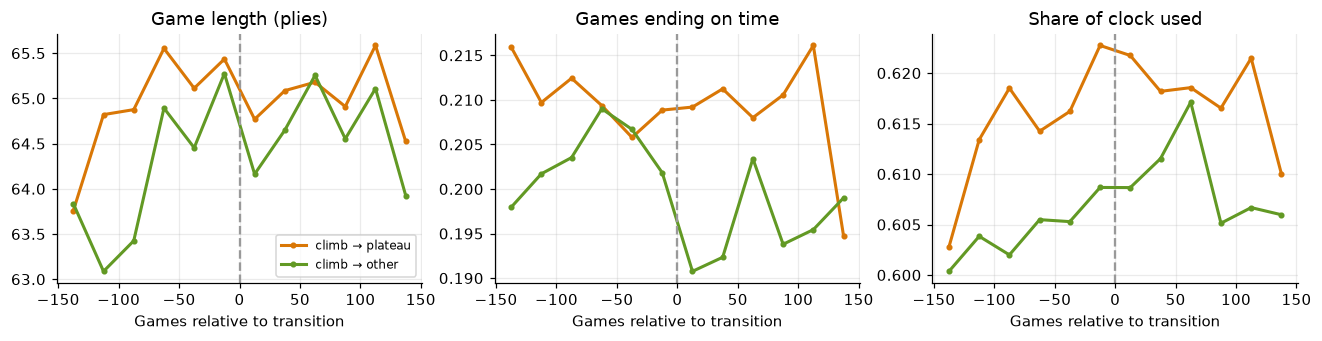

In [16]:
def event_curve(col, rows, half=150, step=25):
    out = []
    for r in rows.itertuples():
        d = gi.loc[r.player]
        for k in range(-half, half, step):
            blk = d.loc[r.onset + k:r.onset + k + step - 1]
            if len(blk) == step:
                val = {"timeout_share": lambda: (blk.status == "outoftime").mean(),
                       "avg_plies": lambda: blk.plies.mean()}.get(col, lambda: blk[col].mean())()
                out.append({"k": k + step / 2, "v": val, "player": r.player})
    return pd.DataFrame(out).groupby("k").v.mean() if out else pd.Series(dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["avg_plies", "timeout_share", "time_use"]):
    for flag, c, lab in [(True, ORANGE, "climb → plateau"), (False, GREEN, "climb → other")]:
        cur = event_curve(col, ev[ev.plateau == flag])
        ax.plot(cur.index, cur.values, color=c, lw=2, marker="o", ms=3, label=lab)
    ax.axvline(0, color="#999", ls="--"); ax.set(title=STYLE[col], xlabel="Games relative to transition")
axes[0].legend(fontsize=8)
save("q4-style-event-study")

## Q5. Can play improve while the rating stays flat? Does accuracy lead rating?

Rating measures results **relative to opponents**, and Lichess pairs players of similar rating. A player whose play improves will usually see their rating rise. But if everyone at their level improves too, or if the improvement is small, the rating can stay flat while the play gets better.

Accuracy comes from Stockfish (fixed node budget, every 4th game of a subset of players), using Lichess's accuracy formula: each move's accuracy drops exponentially with the loss in winning chances. Tactical errors are moves that lose at least 10 points of winning chance (mistakes 10–15, blunders 15+).

250 players, 41,126 analysed games; mean accuracy 86.0%, 4.85 tactical errors per 40 moves


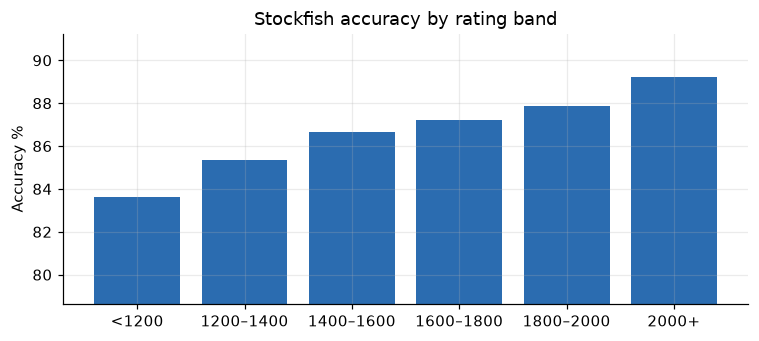

In [17]:
sf_files = sorted((DATA / "sf").glob("*.parquet"))
sf = pd.concat([pd.read_parquet(f) for f in sf_files], ignore_index=True) if sf_files else pd.DataFrame()
HAVE_SF = len(sf) > 500
if HAVE_SF:
    sf = sf.merge(games[["player", "idx", "rating_after", "opp_rating", "rating_before"]], on=["player", "idx"])
    sf["errors"] = (sf.sf_mistakes + sf.sf_blunders) / sf.sf_moves * 40  # per 40 moves
    print(f"{sf.player.nunique()} players, {len(sf):,} analysed games; "
          f"mean accuracy {sf.sf_accuracy.mean():.1f}%, {sf.errors.mean():.2f} tactical errors per 40 moves")
    fig, ax = plt.subplots(figsize=(7, 3.2))
    b = sf.groupby(pd.cut(sf.rating_before, BANDS, labels=LABELS, right=False), observed=True)[["sf_accuracy", "errors"]].mean()
    ax.bar(b.index.astype(str), b.sf_accuracy, color=BLUE); ax.set(ylim=(b.sf_accuracy.min() - 5, b.sf_accuracy.max() + 2),
                                                                 title="Stockfish accuracy by rating band", ylabel="Accuracy %")
    save("accuracy-by-band")

,value
Plateau segments (150+ games) with engine data,270
Mean accuracy change per 100 games during plateau,-0.06
Share of plateaus where accuracy rose,50%
Share with a significant rise (p < .05),3%
One-sample t-test p (mean change = 0),0.38
Mean tactical-error change per 100 games,0.05


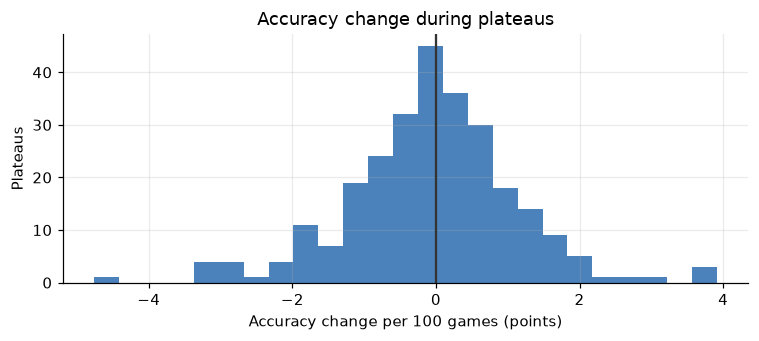

In [18]:
if HAVE_SF:
    flat_segs = segs[(segs.kind == "flat") & (segs.len >= 150)]
    rows = []
    for r in flat_segs.itertuples():
        d = sf[(sf.player == r.player) & (sf.idx >= r.start) & (sf.idx < r.end)]
        if len(d) < 25:
            continue
        sl = stats.linregress(d.idx, d.sf_accuracy)
        se = stats.linregress(d.idx, d.errors)
        rows.append({"player": r.player, "games": r.len, "rating_trend": r.trend,
                     "acc_change_per_100": sl.slope * 100, "acc_p": sl.pvalue,
                     "err_change_per_100": se.slope * 100})
    q5 = pd.DataFrame(rows)
    q5_summary = pd.Series({
        "Plateau segments (150+ games) with engine data": len(q5),
        "Mean accuracy change per 100 games during plateau": round(q5.acc_change_per_100.mean(), 2),
        "Share of plateaus where accuracy rose": f"{(q5.acc_change_per_100 > 0).mean():.0%}",
        "Share with a significant rise (p < .05)": f"{((q5.acc_change_per_100 > 0) & (q5.acc_p < .05)).mean():.0%}",
        "One-sample t-test p (mean change = 0)": round(stats.ttest_1samp(q5.acc_change_per_100, 0).pvalue, 3),
        "Mean tactical-error change per 100 games": round(q5.err_change_per_100.mean(), 3),
    })
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.hist(q5.acc_change_per_100.clip(-8, 8), bins=25, color=BLUE, alpha=.85); ax.axvline(0, color="#333")
    ax.set(title="Accuracy change during plateaus", xlabel="Accuracy change per 100 games (points)", ylabel="Plateaus")
    save("q5-accuracy-during-plateaus")
    display(q5_summary.to_frame("value"))

**Does accuracy improve before rating does?** Each player's history is split into consecutive 50-game blocks. For every block, the change in mean accuracy is compared with the change in rating in the same block, the next block and the one after. Both are centred within each player, so this compares a player with themselves. If accuracy leads, an accuracy gain now should predict a rating gain *later*, even after controlling for the current rating change.

,coef,p
Accuracy change → next block's rating change (controlling for current),1.0816,0.0005
Previous rating change → accuracy change (reverse direction),-0.0056,0.0000


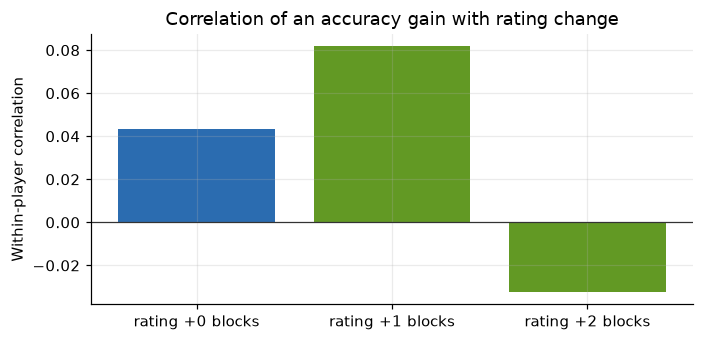

In [19]:
if HAVE_SF:
    sf["block"] = (sf.idx // 50).astype(int)
    blk = (sf.groupby(["player", "block"]).agg(acc=("sf_accuracy", "mean"), err=("errors", "mean"), n=("idx", "size"))
             .query("n >= 8").reset_index())
    rb = games.assign(block=games.idx // 50).groupby(["player", "block"]).rating_after.mean().rename("rating")
    blk = blk.join(rb, on=["player", "block"]).sort_values(["player", "block"])
    g = blk.groupby("player")
    blk["d_acc"] = g.acc.diff(); blk["d_err"] = g.err.diff(); blk["d_rating"] = g.rating.diff()
    for k in (1, 2):
        blk[f"d_rating_next{k}"] = g.rating.shift(-k) - g.rating.shift(-k + 1)
    blk = blk.dropna()
    for c in ["d_acc", "d_err", "d_rating", "d_rating_next1", "d_rating_next2"]:
        blk[c] = blk[c] - blk.groupby("player")[c].transform("mean")
    lead = smf.ols("d_rating_next1 ~ d_acc + d_rating", data=blk).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(blk.player)[0]})
    blk["d_rating_prev"] = blk.groupby("player").d_rating.shift(1)
    rev = smf.ols("d_acc ~ d_rating_prev", data=blk.dropna(subset=["d_rating_prev"])).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(blk.dropna(subset=["d_rating_prev"]).player)[0]})
    lags = {f"rating {k:+d} blocks": stats.pearsonr(blk.d_acc, blk[c])[0]
            for k, c in [(0, "d_rating"), (1, "d_rating_next1"), (2, "d_rating_next2")]}
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    ax.bar(list(lags), list(lags.values()), color=[BLUE, GREEN, GREEN])
    ax.axhline(0, color="#333", lw=.8)
    ax.set(title="Correlation of an accuracy gain with rating change", ylabel="Within-player correlation")
    save("q5-lead-lag")
    q5_lead = pd.DataFrame({
        "coef": [lead.params["d_acc"], rev.params["d_rating_prev"]],
        "p": [lead.pvalues["d_acc"], rev.pvalues["d_rating_prev"]]},
        index=["Accuracy change → next block's rating change (controlling for current)",
               "Previous rating change → accuracy change (reverse direction)"]).round(4)
    display(q5_lead)

## Export for the NeuralGambit dashboard

The final gradient-boosted model is trained on all windows and written to `model.json`. Reference statistics go to `reference.json`: base rates by rating band and by playing frequency, and feature percentiles for the "what is driving this" panel. A check confirms that the exported trees give the same probabilities as scikit-learn.

In [20]:
import json
final = M.fit_final(w)
gb_scores = scores.set_index(["model", "subset"]).loc["All features (gradient boosting)"]
meta = {"gain": GAIN, "window": WINDOW, "flat_trend": FLAT_TREND, "n_windows": len(w), "n_players": int(w.player.nunique()),
        "auc_all": round(gb_scores.loc["All windows", "AUC"], 3), "auc_plateau": round(gb_scores.loc["Plateau windows", "AUC"], 3),
        # ratings the model has seen (1st–99th percentile); the dashboard warns outside this range
        "rating_range": [int(round(v, -1)) for v in np.percentile(w.rating, [1, 99])]}
M.export_gbm(final, OUT / "model.json", extra={"meta": meta})
spec = json.loads((OUT / "model.json").read_text())
diff = np.abs(M.predict_exported(spec, w.head(500)) - final.predict_proba(w.head(500)[FEATURES])[:, 1]).max()
print(f"max difference between exported model and sklearn: {diff:.2e}")

ref = {
    "meta": meta,
    "bands": [{"band": str(b), "plateau_share": round(r.plateau_share, 3), "improve_rate": round(r.improve_rate, 3),
               "improve_rate_flat": round(w[(w.band == b) & w.flat].improve.mean(), 3)} for b, r in q1.iterrows()],
    "base_rate": round(w.improve.mean(), 3), "base_rate_flat": round(w[w.flat].improve.mean(), 3),
    "frequency": [{"label": str(k), "improve_rate": round(v, 3)} for k, v in
                  flat.groupby(pd.cut(flat.games_per_week, bins, labels=labs), observed=True).improve.mean().items()],
    "percentiles": {f: [round(float(v), 3) for v in np.nanpercentile(w[f], [10, 25, 50, 75, 90])] for f in FEATURES},
    "importance": {k: round(float(v), 4) for k, v in imp.sort_values(ascending=False).items()},
}
(OUT / "reference.json").write_text(json.dumps(ref, indent=1))
import shutil
APP_STATIC = ROOT.parents[1] / "static" / "plateau"   # NeuralGambit app
APP_STATIC.mkdir(exist_ok=True)
for f in ("model.json", "reference.json"):
    shutil.copy(OUT / f, APP_STATIC / f)
print("wrote", OUT / "model.json", f"({(OUT / 'model.json').stat().st_size / 1024:.0f} KB)", "and reference.json, copied to", APP_STATIC)

max difference between exported model and sklearn: 9.47e-08
wrote C:\Users\marko\PycharmProjects\Chessmatics\research\plateau\out\model.json (67 KB) and reference.json, copied to C:\Users\marko\PycharmProjects\Chessmatics\static\plateau
